# Climate Comfort Index: DummyRegressor mean baseline

Student **25945320**. Predicts CCI at **+1, +2 and +3 days** from the leakage-audited features
built by the preprocessing notebook.

This notebook is the sklearn-standard floor, not a candidate for deployment. Every later model
must beat it. If a Random Forest, XGBoost or LSTM cannot, it has learned nothing from the
features.

## Hypothesis

`DummyRegressor(strategy="mean")` ignores the feature matrix and emits the training-set mean of
each target for every row. That constant is the loss-minimising prediction when no covariates
are used, so it is the correct null model for MAE and RMSE.

Two stronger naive forecasts are computed alongside it so the floor is not mistaken for the bar:

- **Persistence** carries today's CCI forward. It uses the most recent observation and nothing
  else, and is typically strong at *t*+1.
- **Climatology** predicts the training-set average CCI for that day of the year. It uses the
  seasonal cycle and nothing else.

The dummy mean uses neither today's weather nor the calendar. Persistence and climatology should
beat it; the interesting question is by how much, and whether that gap shrinks as the horizon
lengthens.

## Design

| Choice | Value | Reason |
|---|---|---|
| Algorithm | `DummyRegressor`, `strategy="mean"` | sklearn's canonical regression null model |
| Strategy | One estimator per horizon | Matches the artefact layout of the other CCI notebooks |
| Features | Fitted, then ignored | The estimator API still receives `X`, but the mean does not depend on it |
| Scaling | None | A constant prediction is invariant to feature scale |
| Selection data | Validation split (2024) | The test split is not read in this notebook |
| Metrics | MAE, RMSE, R², prediction spread | `pred_std` must be zero; that is the definition of this baseline |
| Comparisons | Persistence and seasonal climatology | Place the unconditional mean against naive forecasts that do use information |

In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 25945320


def project_root(start: Path | None = None) -> Path:
    """Return the project directory containing ``pyproject.toml``."""
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root from the current directory.")


PROJECT_ROOT = project_root()
DATA_DIR = PROJECT_ROOT / "data" / "processed" / "comfort_climate"
MODEL_DIR = PROJECT_ROOT / "models" / "comfort_climate" / "experiments"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "comfort_climate"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

METADATA = json.loads((DATA_DIR / "cci_feature_metadata.json").read_text())
FEATURE_COLUMNS = METADATA["feature_columns"]
FEATURE_GROUPS = METADATA["feature_groups"]
TARGET_COLUMNS = METADATA["target_columns"]
HORIZONS = METADATA["horizons_days"]
PERSISTENCE_COLUMN = "cci"

EXPERIMENT = "cci_dummy_mean"
ALGORITHM_NAME = "Dummy Regressor (mean)"
MODEL_LABEL = "dummy_mean"
DUMMY_PARAMS = {"strategy": "mean"}

print(f"Features: {len(FEATURE_COLUMNS)} across {len(FEATURE_GROUPS)} families")
print(f"Targets:  {', '.join(TARGET_COLUMNS)}")
print(f"Groups:   {', '.join(FEATURE_GROUPS)}")
print("DummyRegressor will ignore every feature column.")

Features: 86 across 8 families
Targets:  cci_t1, cci_t2, cci_t3
Groups:   same_day_observations, same_day_scores, lags, rolling_statistics, rolling_precipitation, rolling_gusts, deltas, seasonal
DummyRegressor will ignore every feature column.


## 1. Load chronological splits

Only the training and validation files are read. **`sydney_cci_test.csv` is never loaded in this
notebook.** It is reserved for a single final evaluation once a model has been selected, so that
no repeated look at the test period can inform any decision made here.

The preprocessing notebook already applied the chronological split, the warm-up filter and the
3-day embargo at each boundary. Nothing is re-split or shuffled here.

In [2]:
def load_split(name: str) -> pd.DataFrame:
    """Read one chronological split and verify it carries the expected columns."""
    path = DATA_DIR / f"sydney_cci_{name}.csv"
    frame = (
        pd.read_csv(path, parse_dates=["feature_date"])
        .set_index("feature_date")
        .sort_index()
    )
    required = [*FEATURE_COLUMNS, *TARGET_COLUMNS, PERSISTENCE_COLUMN]
    missing = [column for column in required if column not in frame.columns]
    if missing:
        raise ValueError(f"{path.name} is missing columns: {missing[:5]}")
    return frame


splits = {name: load_split(name) for name in ("train", "val")}
X = {name: frame[FEATURE_COLUMNS] for name, frame in splits.items()}
y = {name: frame[TARGET_COLUMNS] for name, frame in splits.items()}

if splits["train"].index.max() >= splits["val"].index.min():
    raise AssertionError("Training dates overlap the validation period.")

for name, frame in splits.items():
    print(f"{name:5} {len(frame):5,} rows  {frame.index.min():%Y-%m-%d} to "
          f"{frame.index.max():%Y-%m-%d}")
print("\nTest split deliberately not loaded.")

train 2,889 rows  2016-01-31 to 2023-12-28
val     363 rows  2024-01-01 to 2024-12-28

Test split deliberately not loaded.


## 2. Persistence and climatology

Two reference forecasts that *do* use information. They are not DummyRegressor variants; they
exist so the unconditional mean can be read against naive forecasts a meteorologist would
actually consider.

**Persistence** carries today's CCI forward unchanged.

**Climatology** predicts the training-set average CCI for that day of the year, smoothed with a
15-day centred window to suppress sampling noise. Centring is acceptable here because the
smoothing is applied to a day-of-year profile derived solely from training data, not to the time
series itself — no future observation enters any prediction.

In [3]:
def climatology_profile(frame: pd.DataFrame, target: str, window: int = 15) -> pd.Series:
    """Mean target by day of year from the training split, smoothed and wrapped at year end."""
    profile = frame.groupby(frame.index.dayofyear)[target].mean().reindex(range(1, 367))
    profile = profile.interpolate(limit_direction="both")
    wrapped = pd.concat([profile, profile, profile])
    smoothed = wrapped.rolling(window, center=True, min_periods=1).mean()
    return smoothed.iloc[len(profile):2 * len(profile)].set_axis(profile.index)


CLIMATOLOGY = {target: climatology_profile(splits["train"], target) for target in TARGET_COLUMNS}


def naive_predictions(name: str, target: str) -> dict[str, np.ndarray]:
    """Return persistence and climatology forecasts for one split and horizon."""
    frame = splits[name]
    return {
        "persistence": frame[PERSISTENCE_COLUMN].to_numpy(),
        "climatology": CLIMATOLOGY[target].reindex(frame.index.dayofyear).to_numpy(),
    }


def regression_metrics(y_true, y_pred) -> dict[str, float]:
    """MAE, RMSE, R2 and prediction spread on the 0-100 CCI scale."""
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": float(r2_score(y_true, y_pred)),
        "pred_std": float(np.std(y_pred)),
    }


naive_rows = []
for target in TARGET_COLUMNS:
    for label, prediction in naive_predictions("val", target).items():
        naive_rows.append(
            {"target": target, "model": label,
             **regression_metrics(splits["val"][target], prediction)}
        )
NAIVE = pd.DataFrame(naive_rows).set_index(["target", "model"])
print("Validation naive forecasts (information-using floors):\n")
NAIVE

Validation naive forecasts (information-using floors):



mae   rmse     r2  pred_std
target model                                    
cci_t1 persistence 7.562  9.928  0.185    10.937
       climatology 7.627 10.135  0.151     3.723
cci_t2 persistence 8.624 11.521 -0.094    10.937
       climatology 7.640 10.141  0.152     3.722
cci_t3 persistence 9.162 12.015 -0.188    10.937
       climatology 7.651 10.143  0.153     3.720

## 3. Fit the mean dummy

One `DummyRegressor(strategy="mean")` per horizon. sklearn still requires a feature matrix, so
the training features are passed in, but the fitted constant is exactly the training-set mean of
that target. A native multi-output dummy is fitted as a check: it must recover the same three
constants, because the mean of a column does not depend on the other columns.

In [4]:
def fit_per_horizon() -> dict[int, DummyRegressor]:
    """Fit one mean dummy per horizon against the shared feature matrix."""
    fitted = {}
    for h in HORIZONS:
        model = DummyRegressor(**DUMMY_PARAMS)
        model.fit(X["train"][FEATURE_COLUMNS], y["train"][f"cci_t{h}"])
        fitted[h] = model
    return fitted


models = fit_per_horizon()

multi_output = DummyRegressor(**DUMMY_PARAMS)
multi_output.fit(X["train"][FEATURE_COLUMNS], y["train"][TARGET_COLUMNS])

constant_rows = []
for index, h in enumerate(HORIZONS):
    target = f"cci_t{h}"
    per_horizon_mean = float(np.asarray(models[h].constant_).reshape(-1)[0])
    multi_output_mean = float(np.asarray(multi_output.constant_).reshape(-1)[index])
    train_mean = float(y["train"][target].mean())
    constant_rows.append({
        "target": target,
        "train_mean": train_mean,
        "per_horizon_constant": per_horizon_mean,
        "multi_output_constant": multi_output_mean,
        "abs_diff": abs(per_horizon_mean - multi_output_mean),
    })

constants = pd.DataFrame(constant_rows).set_index("target")
print("Fitted constants must match the training-set mean of each target:\n")
print(constants.to_string())
print("\nA DummyRegressor mean baseline has no hyperparameters to tune and no features to rank.")

Fitted constants must match the training-set mean of each target:

        train_mean  per_horizon_constant  multi_output_constant  abs_diff
target                                                                   
cci_t1      71.306                71.306                 71.306     0.000
cci_t2      71.306                71.306                 71.306     0.000
cci_t3      71.299                71.299                 71.299     0.000

A DummyRegressor mean baseline has no hyperparameters to tune and no features to rank.


## 4. Evaluation against persistence and climatology

Metrics for every horizon on validation data. The dummy's `pred_std` must be zero: every
prediction is the same number. R² of an unconditional mean is at most zero on data whose mean
matches the training mean, and is slightly negative when the validation mean has drifted.

`pred_std` is the direct test used in the other notebooks for a model that has retreated to the
mean. This notebook is that retreat, by construction. Later models are useful only to the extent
their spread rises above zero *and* their MAE falls below this table.

Validation performance:

                     mae   rmse     r2  pred_std  observed_std
target model                                                  
cci_t1 dummy_mean  8.767 11.128 -0.023     0.000        11.001
       persistence 7.562  9.928  0.185    10.937        11.001
       climatology 7.627 10.135  0.151     3.723        11.001
cci_t2 dummy_mean  8.780 11.140 -0.023     0.000        11.014
       persistence 8.624 11.521 -0.094    10.937        11.014
       climatology 7.640 10.141  0.152     3.722        11.014
cci_t3 dummy_mean  8.793 11.145 -0.022     0.000        11.023
       persistence 9.162 12.015 -0.188    10.937        11.023
       climatology 7.651 10.143  0.153     3.720        11.023

How much persistence and climatology beat the unconditional mean
(positive reduction means the naive forecast is better than DummyRegressor):

                       dummy_mae  naive_mae  naive_mae_reduction relative
target naive_forecast                                           

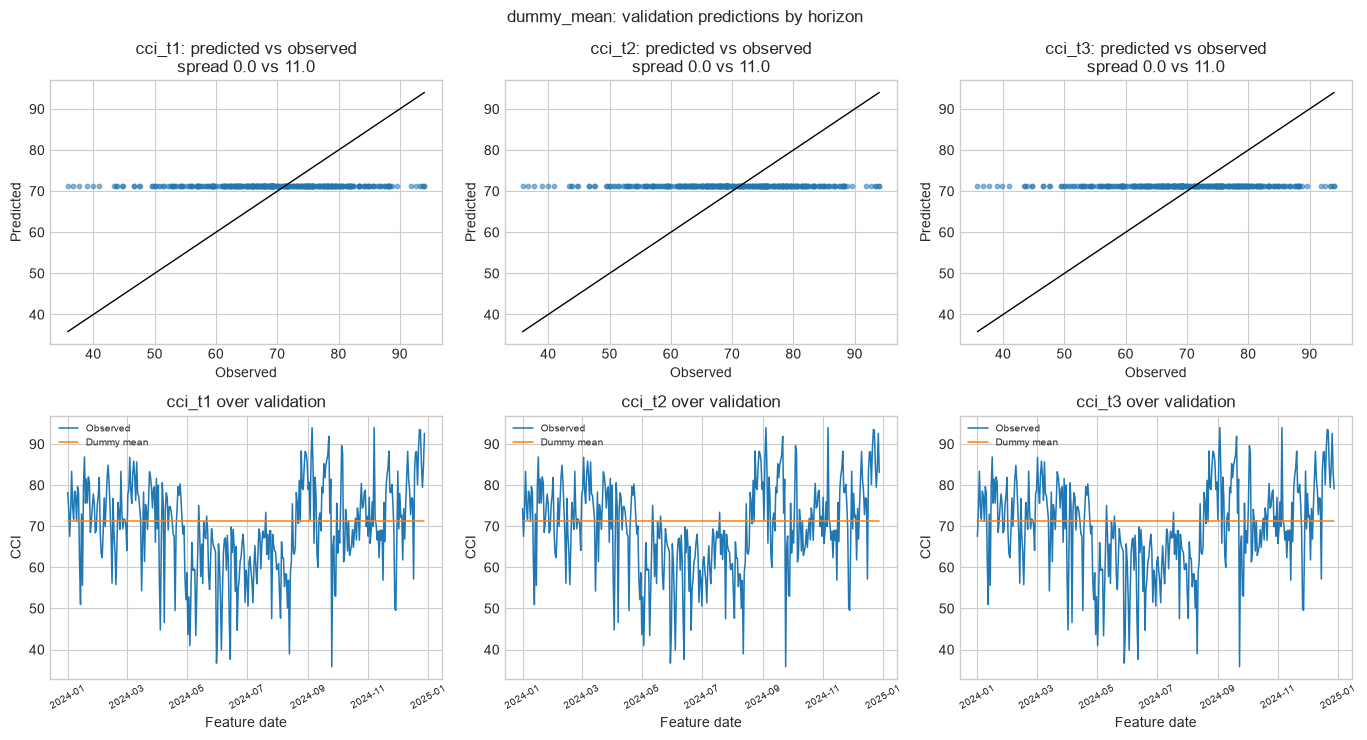

In [5]:
rows = []
predictions = {}
for h in HORIZONS:
    target = f"cci_t{h}"
    observed = splits["val"][target].to_numpy()
    prediction = models[h].predict(X["val"][FEATURE_COLUMNS])
    predictions[h] = prediction
    rows.append({"target": target, "model": MODEL_LABEL,
                 **regression_metrics(observed, prediction)})
    for label, baseline in naive_predictions("val", target).items():
        rows.append({"target": target, "model": label,
                     **regression_metrics(observed, baseline)})

results = pd.DataFrame(rows).set_index(["target", "model"])
results["observed_std"] = [
    np.std(splits["val"][target]) for target in results.index.get_level_values("target")
]
print("Validation performance:\n")
print(results.to_string())

comparison = []
for h in HORIZONS:
    target = f"cci_t{h}"
    dummy_mae = results.loc[(target, MODEL_LABEL), "mae"]
    for baseline in ("persistence", "climatology"):
        baseline_mae = results.loc[(target, baseline), "mae"]
        comparison.append({
            "target": target,
            "naive_forecast": baseline,
            "dummy_mae": dummy_mae,
            "naive_mae": baseline_mae,
            "naive_mae_reduction": dummy_mae - baseline_mae,
            "relative": (dummy_mae - baseline_mae) / dummy_mae,
        })
comparison = pd.DataFrame(comparison).set_index(["target", "naive_forecast"])
print("\nHow much persistence and climatology beat the unconditional mean")
print("(positive reduction means the naive forecast is better than DummyRegressor):\n")
print(comparison.to_string(formatters={"relative": "{:.1%}".format}))

fig, axes = plt.subplots(2, len(HORIZONS), figsize=(4.6 * len(HORIZONS), 7.5))
for column, h in enumerate(HORIZONS):
    target = f"cci_t{h}"
    observed = splits["val"][target].to_numpy()
    prediction = predictions[h]
    scatter_axis = axes[0, column]
    scatter_axis.scatter(observed, prediction, s=10, alpha=0.5)
    limits = [min(observed.min(), prediction.min()), max(observed.max(), prediction.max())]
    scatter_axis.plot(limits, limits, color="black", lw=1)
    scatter_axis.set(
        title=(f"{target}: predicted vs observed\n"
               f"spread {np.std(prediction):.1f} vs {np.std(observed):.1f}"),
        xlabel="Observed",
        ylabel="Predicted",
    )
    series_axis = axes[1, column]
    series_axis.plot(splits["val"].index, observed, lw=1.1, label="Observed")
    series_axis.plot(splits["val"].index, prediction, lw=1.1, label="Dummy mean")
    series_axis.set(title=f"{target} over validation", xlabel="Feature date", ylabel="CCI")
    series_axis.tick_params(axis="x", labelrotation=30, labelsize=7)
    series_axis.legend(fontsize=7)
fig.suptitle(f"{MODEL_LABEL}: validation predictions by horizon", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{EXPERIMENT}-validation.png", dpi=150, bbox_inches="tight")
plt.show()

The scatter should be a horizontal line at the training mean. The series plot should sit flat
through the seasonal cycle. Both are the visual signature of a mean dummy, and they are what a
later model must not look like if it is to be considered useful.

Validation MAE by horizon:

model   dummy_mean  persistence  climatology
target                                      
cci_t1       8.767        7.562        7.627
cci_t2       8.780        8.624        7.640
cci_t3       8.793        9.162        7.651


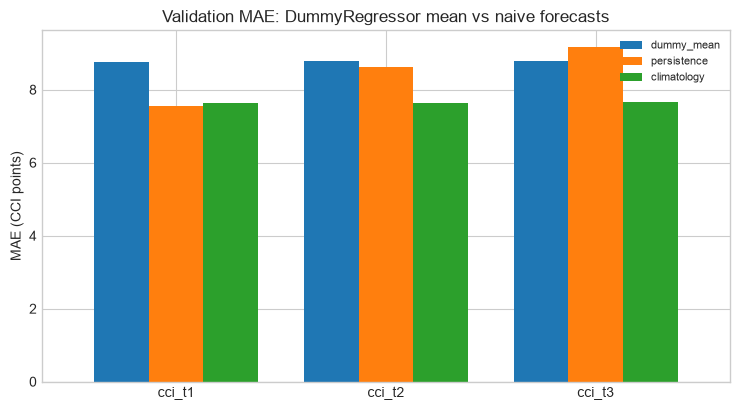

In [6]:
mae_table = results["mae"].unstack()[["dummy_mean", "persistence", "climatology"]]
print("Validation MAE by horizon:\n")
print(mae_table.to_string())

fig, axis = plt.subplots(figsize=(7.5, 4.2))
mae_table.plot.bar(ax=axis, width=0.78)
axis.set(title="Validation MAE: DummyRegressor mean vs naive forecasts",
         xlabel="", ylabel="MAE (CCI points)")
axis.tick_params(axis="x", labelrotation=0)
axis.legend(title="", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{EXPERIMENT}-mae-comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Train / validation gap

For a mean dummy the training MAE is the mean absolute deviation of the training target around
its own mean. Validation MAE is the same quantity on 2024, measured against the *training* mean.
A large gap would mean 2024's CCI level drifted from 2016–2023, not that the dummy overfit —
there is nothing to overfit.

In [7]:
gap_rows = []
for h in HORIZONS:
    target = f"cci_t{h}"
    for name in ("train", "val"):
        prediction = models[h].predict(X[name][FEATURE_COLUMNS])
        gap_rows.append({
            "target": target,
            "split": name,
            **regression_metrics(splits[name][target], prediction),
        })

gap = pd.DataFrame(gap_rows).set_index(["target", "split"])
print(gap.to_string())

mae_gap = gap["mae"].unstack()
mae_gap["ratio"] = mae_gap["val"] / mae_gap["train"]
print("\nValidation-to-training MAE ratio (near 1 means the 2024 level matches the training mean):")
print(mae_gap.to_string())

print("\nValidation mean vs training constant:")
for h in HORIZONS:
    target = f"cci_t{h}"
    train_constant = float(np.asarray(models[h].constant_).reshape(-1)[0])
    val_mean = float(splits["val"][target].mean())
    print(f"  {target}: train mean {train_constant:.3f}  val mean {val_mean:.3f}  "
          f"drift {val_mean - train_constant:+.3f}")

               mae   rmse     r2  pred_std
target split                              
cci_t1 train 7.914 10.259  0.000     0.000
       val   8.767 11.128 -0.023     0.000
cci_t2 train 7.914 10.259  0.000     0.000
       val   8.780 11.140 -0.023     0.000
cci_t3 train 7.911 10.256  0.000     0.000
       val   8.793 11.145 -0.022     0.000

Validation-to-training MAE ratio (near 1 means the 2024 level matches the training mean):
split   train   val  ratio
target                    
cci_t1  7.914 8.767  1.108
cci_t2  7.914 8.780  1.109
cci_t3  7.911 8.793  1.111

Validation mean vs training constant:
  cci_t1: train mean 71.306  val mean 69.626  drift -1.679
  cci_t2: train mean 71.306  val mean 69.640  drift -1.666
  cci_t3: train mean 71.299  val mean 69.653  drift -1.647


## 6. Saved artefacts

One dummy per horizon is written, together with a metadata file shaped for the
`/model-metadata` endpoint. Feature importance is empty: the estimator does not use features.
The feature column list is still recorded so a later comparison notebook can score every model
on the same matrix.

The test split remains unused.

In [8]:
artefacts = []
for h in HORIZONS:
    target = f"cci_t{h}"
    path = MODEL_DIR / f"{EXPERIMENT}_h{h}.joblib"
    joblib.dump(models[h], path)
    artefacts.append({
        "target": "Climate Comfort Index",
        "target_column": target,
        "prediction_type": "regression",
        "algorithm": ALGORITHM_NAME,
        "forecast_horizon": f"{h} Day{'s' if h > 1 else ''}",
        "model_file": path.name,
        "hyperparameters": DUMMY_PARAMS,
        "features": FEATURE_COLUMNS,
        "feature_importance": {},
        "constant": float(np.asarray(models[h].constant_).reshape(-1)[0]),
        "validation_metrics": results.loc[(target, MODEL_LABEL)].drop("observed_std").to_dict(),
        "baseline_metrics": {
            baseline: results.loc[(target, baseline)].drop("observed_std").to_dict()
            for baseline in ("persistence", "climatology")
        },
    })

metadata_path = MODEL_DIR / f"{EXPERIMENT}_metadata.json"
metadata_path.write_text(json.dumps({
    "experiment": EXPERIMENT,
    "student_id": "25945320",
    "algorithm": ALGORITHM_NAME,
    "feature_columns": FEATURE_COLUMNS,
    "feature_column_order_is_significant": False,
    "notes": (
        "DummyRegressor(strategy='mean') ignores features and emits the training-set "
        "mean of each target. Persistence and climatology are stronger naive forecasts "
        "included for comparison only."
    ),
    "split_boundaries": METADATA["split_boundaries"],
    "embargo_days": METADATA["embargo_days"],
    "evaluated_on": ["train", "val"],
    "held_out": ["test"],
    "models": artefacts,
}, indent=2))

for h in HORIZONS:
    print(f"Saved model h{h}: {(MODEL_DIR / f'{EXPERIMENT}_h{h}.joblib').relative_to(PROJECT_ROOT)}")
print(f"Saved metadata: {metadata_path.relative_to(PROJECT_ROOT)}")
print("\nTest split was not used in this notebook.")

Saved model h1: models/comfort_climate/cci_dummy_mean_h1.joblib
Saved model h2: models/comfort_climate/cci_dummy_mean_h2.joblib
Saved model h3: models/comfort_climate/cci_dummy_mean_h3.joblib
Saved metadata: models/comfort_climate/cci_dummy_mean_metadata.json

Test split was not used in this notebook.


## 7. Conclusions

Points to carry into the report and the model-comparison notebook:

- **This is the floor.** MAE, RMSE and R² in section 4 are the numbers every later CCI model
  must improve on. A model that cannot beat `DummyRegressor(strategy="mean")` has not used the
  features.
- **Persistence is the real short-horizon bar.** If persistence beats the dummy by a wide
  margin at *t*+1, then today's CCI already contains most of the easy signal. A learned model
  that only just beats the dummy, but loses to persistence, is not yet useful.
- **Climatology is the seasonal bar.** The dummy is a single number for the whole year.
  Climatology is allowed to vary by day of year. The gap between them is the value of seasonality
  alone.
- **Dispersion is zero.** `pred_std = 0` is correct for this estimator. Any later model whose
  prediction spread collapses toward zero is behaving like this dummy, even if it is a forest or
  a network.
- **No leakage, no tuning.** The dummy cannot leak future information and cannot overfit. Its
  train/validation gap, if any, is a statement about 2024's climate relative to 2016–2023.

The test split has still not been touched. It should be used exactly once, after a single model
has been selected on validation performance across all experiment notebooks.